In [ ]:

from google.colab import files
uploaded = files.upload()


Saving Rheumatic and Autoimmune Disease Dataset.xlsx to Rheumatic and Autoimmune Disease Dataset.xlsx


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_name = next(iter(uploaded))
df = pd.read_excel(file_name)

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Shape: (12085, 15)

First 5 Rows:


,Age,Gender,ESR,CRP,RF,Anti-CCP,HLA-B27,ANA,Anti-Ro,Anti-La,Anti-dsDNA,Anti-Sm,C3,C4,Disease
0,70,Male,39.0,18.6,34.2,29.9,Positive,Negative,Positive,Negative,Positive,Positive,NaN,27.0,Rheumatoid Arthritis
1,39,Female,26.0,21.7,35.5,28.9,Negative,NaN,Positive,NaN,Positive,NaN,100.0,66.0,Rheumatoid Arthritis
2,36,Female,41.0,15.6,21.3,21.3,Negative,Negative,NaN,Positive,Negative,NaN,158.0,12.0,Rheumatoid Arthritis
3,35,Male,43.0,23.4,26.0,39.0,NaN,NaN,Positive,Positive,NaN,NaN,119.0,41.0,Rheumatoid Arthritis
4,37,Female,30.0,NaN,38.1,30.8,Positive,Negative,Positive,Negative,Positive,Negative,144.0,49.0,Rheumatoid Arthritis



Column Names:
['Age', 'Gender', 'ESR', 'CRP', 'RF', 'Anti-CCP', 'HLA-B27', 'ANA', 'Anti-Ro', 'Anti-La', 'Anti-dsDNA', 'Anti-Sm', 'C3', 'C4', 'Disease']

Missing Values:
Age              0
Gender           0
ESR           1088
CRP           2417
RF            1329
Anti-CCP      3263
HLA-B27       1934
ANA           3746
Anti-Ro       2900
Anti-La       3021
Anti-dsDNA    4713
Anti-Sm       5197
C3            1692
C4            2054
Disease          0
dtype: int64


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Target column
df = df.dropna(subset=['Disease'])

X = df.drop('Disease', axis=1)
y = df['Disease']

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=np.number).columns
categorical_features = X.select_dtypes(exclude=np.number).columns

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Data Preprocessing Completed!")


Data Preprocessing Completed!


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (9668, 14)
Testing Data: (2417, 14)


In [ ]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

linear_svm = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('svm', SVC(kernel='linear', class_weight='balanced'))
])

linear_svm.fit(X_train, y_train)

linear_pred = linear_svm.predict(X_test)

linear_accuracy = accuracy_score(y_test, linear_pred)
linear_f1 = f1_score(y_test, linear_pred, average='weighted')

print("LINEAR SVM RESULTS")
print("Accuracy:", round(linear_accuracy * 100, 2), "%")
print("Weighted F1 Score:", round(linear_f1, 4))


LINEAR SVM RESULTS
Accuracy: 78.86 %
Weighted F1 Score: 0.7917


In [ ]:

poly_svm = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('svm', SVC(
        kernel='poly',
        degree=3,
        class_weight='balanced'
    ))
])

poly_svm.fit(X_train, y_train)

poly_pred = poly_svm.predict(X_test)

poly_accuracy = accuracy_score(y_test, poly_pred)
poly_f1 = f1_score(y_test, poly_pred, average='weighted')

print("POLYNOMIAL SVM RESULTS")
print("Accuracy:", round(poly_accuracy * 100, 2), "%")
print("Weighted F1 Score:", round(poly_f1, 4))


POLYNOMIAL SVM RESULTS
Accuracy: 79.64 %
Weighted F1 Score: 0.8003


In [ ]:

rbf_svm = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('svm', SVC(
        kernel='rbf',
        class_weight='balanced'
    ))
])

rbf_svm.fit(X_train, y_train)

rbf_pred = rbf_svm.predict(X_test)

rbf_accuracy = accuracy_score(y_test, rbf_pred)
rbf_f1 = f1_score(y_test, rbf_pred, average='weighted')

print("RBF SVM RESULTS")
print("Accuracy:", round(rbf_accuracy * 100, 2), "%")
print("Weighted F1 Score:", round(rbf_f1, 4))


RBF SVM RESULTS
Accuracy: 80.47 %
Weighted F1 Score: 0.8072


In [ ]:

sigmoid_svm = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('svm', SVC(
        kernel='sigmoid',
        class_weight='balanced'
    ))
])

sigmoid_svm.fit(X_train, y_train)

sigmoid_pred = sigmoid_svm.predict(X_test)

sigmoid_accuracy = accuracy_score(y_test, sigmoid_pred)
sigmoid_f1 = f1_score(y_test, sigmoid_pred, average='weighted')

print("SIGMOID SVM RESULTS")
print("Accuracy:", round(sigmoid_accuracy * 100, 2), "%")
print("Weighted F1 Score:", round(sigmoid_f1, 4))


SIGMOID SVM RESULTS
Accuracy: 69.14 %
Weighted F1 Score: 0.6964


In [ ]:

results = pd.DataFrame({
    'Kernel': ['Linear', 'Polynomial', 'RBF', 'Sigmoid'],
    'Accuracy': [
        linear_accuracy,
        poly_accuracy,
        rbf_accuracy,
        sigmoid_accuracy
    ],
    'F1 Score': [
        linear_f1,
        poly_f1,
        rbf_f1,
        sigmoid_f1
    ]
})

display(results)


,Kernel,Accuracy,F1 Score
0,Linear,0.788581,0.791708
1,Polynomial,0.796442,0.800300
2,RBF,0.804717,0.807190
3,Sigmoid,0.691353,0.696431


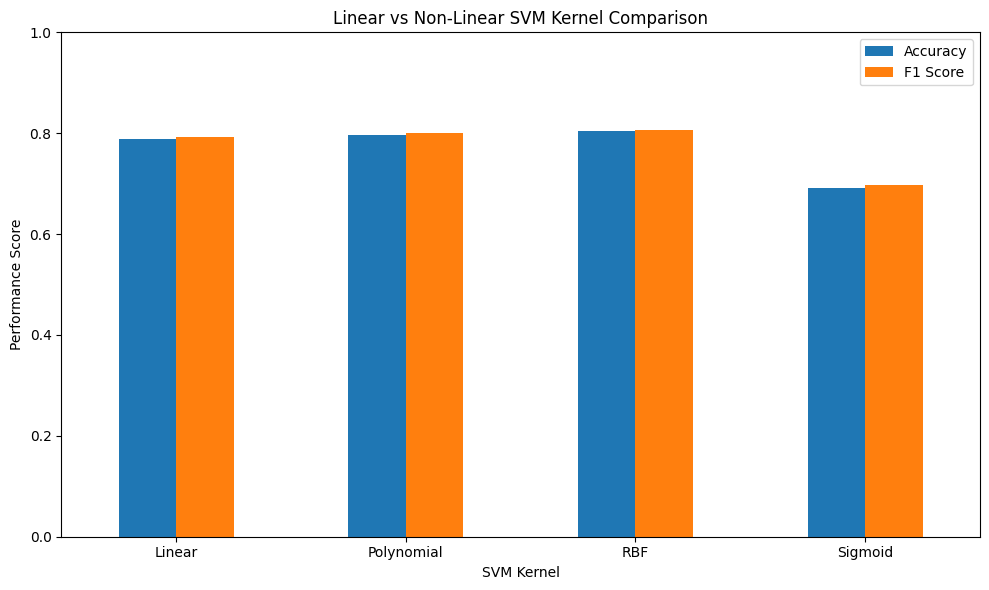

In [ ]:

results.set_index('Kernel')[['Accuracy', 'F1 Score']].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Linear vs Non-Linear SVM Kernel Comparison')
plt.xlabel('SVM Kernel')
plt.ylabel('Performance Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

best_index = results['Accuracy'].idxmax()
best_kernel = results.loc[best_index, 'Kernel']

print("Best Performing Kernel:", best_kernel)
print("Best Accuracy:",
      round(results.loc[best_index, 'Accuracy'] * 100, 2), "%")

models = {
    'Linear': (linear_svm, linear_pred),
    'Polynomial': (poly_svm, poly_pred),
    'RBF': (rbf_svm, rbf_pred),
    'Sigmoid': (sigmoid_svm, sigmoid_pred)
}

best_model, best_pred = models[best_kernel]


Best Performing Kernel: RBF
Best Accuracy: 80.47 %


In [ ]:

from sklearn.metrics import classification_report

print("BEST KERNEL CLASSIFICATION REPORT")
print(classification_report(y_test, best_pred))


BEST KERNEL CLASSIFICATION REPORT
                              precision    recall  f1-score   support

      Ankylosing Spondylitis       0.65      0.55      0.60       425
                      Normal       0.96      0.80      0.87       321
         Psoriatic Arthritis       0.83      0.86      0.84       357
          Reactive Arthritis       0.43      0.90      0.58       103
        Rheumatoid Arthritis       0.86      0.80      0.83       570
          Sjögren's Syndrome       0.84      0.93      0.89       370
Systemic Lupus Erythematosus       0.96      0.94      0.95       271

                    accuracy                           0.80      2417
                   macro avg       0.79      0.83      0.79      2417
                weighted avg       0.82      0.80      0.81      2417



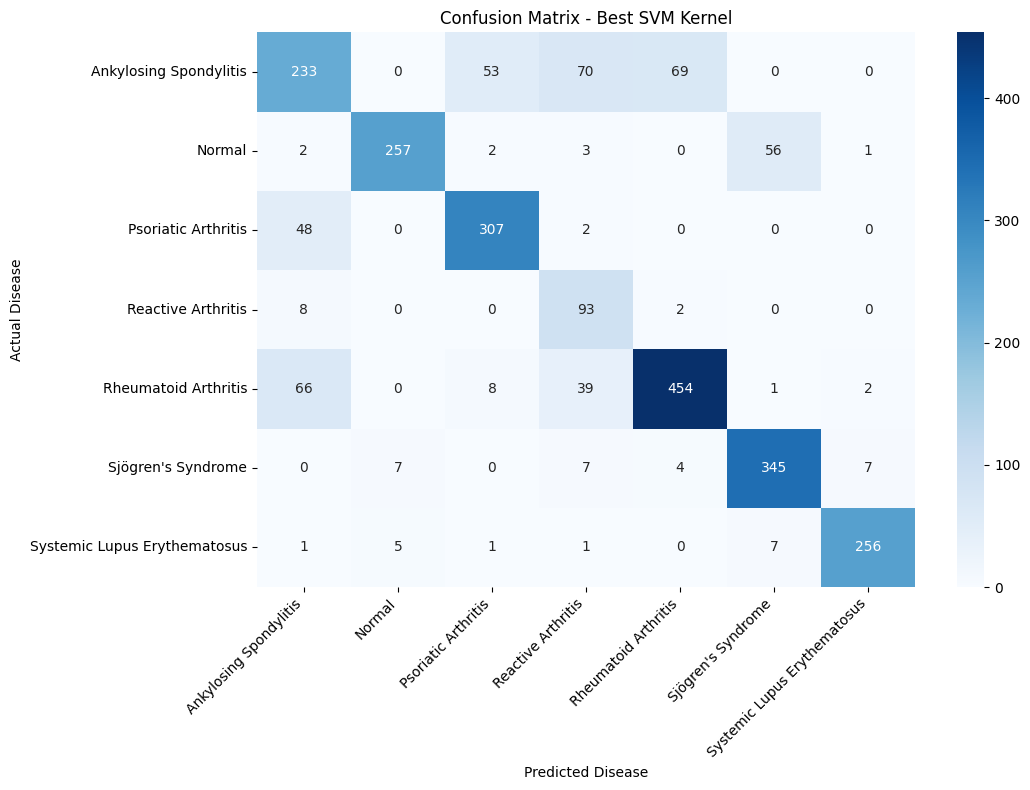

In [ ]:

# STEP 13: Confusion Matrix Visualization

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=best_model.classes_,
    yticklabels=best_model.classes_
)

plt.title('Confusion Matrix - Best SVM Kernel')
plt.xlabel('Predicted Disease')
plt.ylabel('Actual Disease')

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


In [ ]:

results.to_csv('svm_kernel_comparison.csv', index=False)

results.to_excel('svm_kernel_comparison.xlsx', index=False)

print("Results files saved successfully!")


Results files saved successfully!
